In [10]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import torch
import math
%matplotlib inline

In [ ]:
class Value:
    def __init__(self,data, _children = (), _op = '', label = ''):
        self.data = data
        self._prev = set(_children)
        self._backward = lambda: None
        self._op = _op
        self.label = label
        self.gradi = 0.0
    
    def __repr__(self):
        return(f'(value = {self.data})')

    def __add__(self, other):
        out = Value(self.data + other.data, (self,other ), '+' )

        def _backward():
            self.gradi += 1.0 * out.gradi
            other.gradi += 1.0 * out.gradi
        out._backward = _backward
        return out

    def __mul__(self, other):
        out = Value(self.data * other.data, (self,other ), '*')
        def _backward():
            self.gradi += other.data * out.gradi
            other.gradi += self.data * out.gradi
        out._backward = _backward
        return out

    def tanh(self):
        x = self.data
        t = ((math.exp(2*x) - 1) / (math.exp(2*x) + 1))
        out = Value(t, (self,),'tanh')
        def _backward():
            self.gradi += (1 - t**2) * out.gradi
        out._backward = _backward
        return out
    def backward(self):
        # Implement a Topological Search to Create Order of Operation (Forward Pass Before Backprop)
        
        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)
        # initialize gradient to be 1.0
        self.gradi = 1.0
        for i in reversed(topo):
            i._backward()

In [12]:
a = Value(2.0, label='a') 
b = Value(-3.0, label='b')
c = Value(10.0, label = 'c')
d = a*b; d.label = 'd'
e = d + c; e.label = 'e'

e


(value = 4.0)

In [13]:
from graphviz import Digraph
def trace(root):
    nodes , edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child,v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir':'LR'})
    nodes , edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        dot.node(name = uid, label = '{%s |data %.4f| gradi %.4f}' % (n.label,n.data,n.gradi), shape = 'record')
        if n._op:
            dot.node(name = uid + n._op, label = n._op)
            dot .edge(uid + n._op,uid)

    for n1,n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2._op )
    return dot 

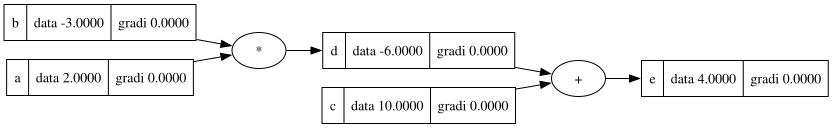

In [14]:
draw_dot(e)


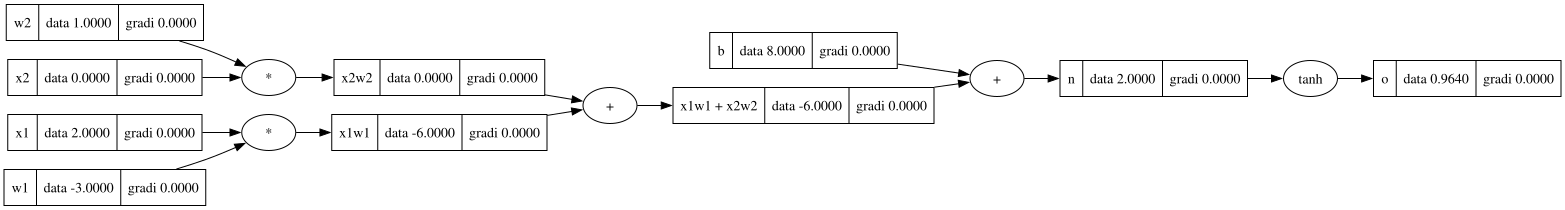

In [15]:
#inputs 
x1 = Value(2.0, label= 'x1')
x2 = Value(0.0, label= 'x2')

#weights 
w1 = Value(-3.0, label= 'w1')
w2 = Value(1.0, label= 'w2')

# bias
b = Value(8,label= 'b')

# x1w1 + x2w2
x1w1 = x1 * w1; x1w1.label = 'x1w1'
x2w2 = x2 * w2; x2w2.label = 'x2w2'

x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1w1 + x2w2'

n = x1w1x2w2 + b; n.label = 'n'

o = n.tanh(); o.label = 'o'

draw_dot(o)



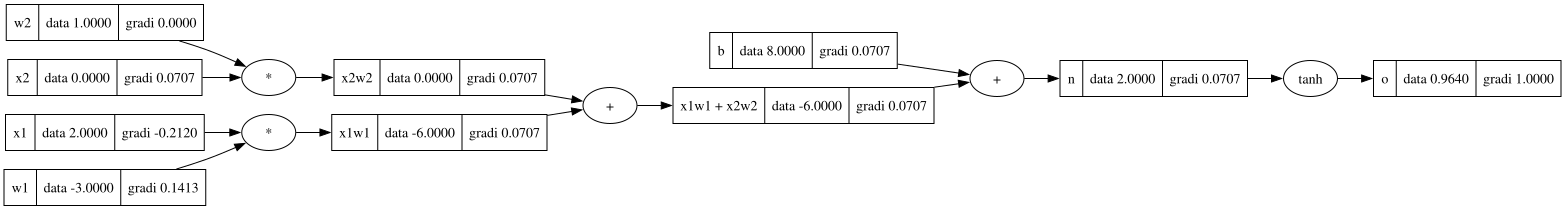

In [18]:
o.backward()
draw_dot(o)